# Eripolarc Knowledge Graph: step by step

In this notebook a small **knowledge graph** is built from news articles and then use it to answer questions (the core of a GraphRAG chatbot).

**The pipeline**

```
articles_all.json
   │  1. load + explore
   ▼
spaCy NER  ──►  entities (people, organisations, places...)
   │  2. extract
   ▼
Neo4j       ──►  (Entity)-[:MENTIONED_IN]->(Article)
   │  3. load into the graph
   ▼
(Entity)-[:CO_OCCURS_WITH {weight}]-(Entity)
   │  4. connect entities that appear together
   ▼
communities  ──►  groups of related entities
   │  5. detect
   ▼
retrieve + ask  ──►  answer + sources
      6. chatbot
```

**Before you start**
- `pip install neo4j pandas python-dotenv spacy networkx matplotlib`
- `python -m spacy download en_core_web_sm`
- a `.env` file with `NEO4J_URI`, `NEO4J_USERNAME`, `NEO4J_PASSWORD`
- a running Neo4j instance (Aura free tier is fine)

## Step 0: Setup

In [2]:
import hashlib
import itertools
import os
import re
from collections import defaultdict

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
from dotenv import load_dotenv
from neo4j import GraphDatabase

load_dotenv(override=True)   # override=True: the .env wins over old shell variables

ARTICLES_PATH = "/root/projects/llm_eripolarc_database/data/articles_all.json"
N_ARTICLES = 50              # keep small while learning; set to None for everything

### Check the Neo4j connection

If this fails with `Name or service not known`, your Aura instance is probably **paused or deleted**. Open the Aura console, resume it (or create a new one) and update `.env`.

In [3]:
driver = GraphDatabase.driver(
    os.environ["NEO4J_URI"],
    auth=(os.environ["NEO4J_USERNAME"], os.environ["NEO4J_PASSWORD"]),
)
driver.verify_connectivity()
print("Connected to", os.environ["NEO4J_URI"])


def run(query, **params):
    """Run one Cypher query and return the rows as a list of dicts."""
    with driver.session() as session:
        return session.run(query, **params).data()

Connected to neo4j+s://76e38d4d.databases.neo4j.io


## Step 1: Load and explore the articles

Each row is one scraped article. We keep English articles that have both a title and a text, and give each article a stable **id** (a hash of its link, or its title if there is no link). The id will be the key of the `Article` node, so re-running the notebook never creates duplicates.

In [4]:
def make_article_id(link, title):
    key = str(link if pd.notna(link) else title).strip()
    return hashlib.sha1(key.encode("utf-8")).hexdigest()


df = pd.read_json(ARTICLES_PATH)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 35490 entries, 0 to 35489
Data columns (total 16 columns):
 #   Column       Non-Null Count  Dtype              
---  ------       --------------  -----              
 0   source       35490 non-null  str                
 1   link         35490 non-null  str                
 2   title        35490 non-null  str                
 3   author       35490 non-null  str                
 4   date         34259 non-null  datetime64[us]     
 5   date_raw     35490 non-null  str                
 6   text         35490 non-null  str                
 7   image        35490 non-null  str                
 8   images       35490 non-null  object             
 9   category     35490 non-null  str                
 10  tags         30083 non-null  object             
 11  language     30083 non-null  str                
 12  script       30083 non-null  str                
 13  attachments  30083 non-null  object             
 14  extra        30083 non-null  obje

In [5]:
df = df.dropna(subset=["title", "text"])
df = df[df["language"].eq("en")].copy()
df["article_id"] = [make_article_id(l, t) for l, t in zip(df["link"], df["title"])]
df = df.drop_duplicates("article_id").reset_index(drop=True)

if N_ARTICLES:
    df = df.head(N_ARTICLES)

print(f"{len(df)} English articles")
df[["title", "source", "date_raw"]].head()

50 English articles


,title,source,date_raw
0,"Peace Through Sovereignty, Truth, and Mutual R...",awate,2026-11-01T08:20:26
1,The Unheard Language: When Speaking Is Not Lis...,farajat_en,2026-10-31T03:51:02
2,"Eritrea–Russia Talks Focus on Ports, Railways ...",mesobjournal,2026-10-31T19:44:44.715Z
3,From Abiy’s Medemer to Gaddafi’s Green Book: T...,erisat,2026-10-30T14:15:14
4,"Mosque of AdiKwala, Eritrea",eritreanpost,2026-10-30T13:10:52


## Step 2: Extract entities with spaCy

spaCy's named-entity recognition (NER) labels spans of text. We keep six labels:

| Label | Meaning |
|---|---|
| `PERSON` | people |
| `ORG` | organisations |
| `GPE` | countries, cities, states |
| `LOC` | other locations (seas, mountains...) |
| `EVENT` | named events |
| `FAC` | buildings, ports, airports... |

### 2a. Try it on a single article

In [6]:
import spacy

nlp = spacy.load("en_core_web_sm", disable=["parser", "lemmatizer"])
ENTITY_LABELS = {"PERSON", "ORG", "GPE", "LOC", "EVENT", "FAC"}

sample = df.iloc[0]
doc = nlp(f"{sample.title}\n{sample.text[:3000]}")

print(sample.title, "\n")
for ent in doc.ents:
    if ent.label_ in ENTITY_LABELS:
        print(f"{ent.label_:7} {ent.text}")

Peace Through Sovereignty, Truth, and Mutual Respect 

GPE     Truth
GPE     Eritrea
GPE     Ethiopia
GPE     Eritrea
GPE     Ethiopia
GPE     Russia
PERSON  Sergey Lavrov
PERSON  Abiy Ahmed
PERSON  Isaias Afwerki
GPE     Moscow
PERSON  Abiy Ahmed
ORG     Sukhoi
GPE     Moscow
GPE     Eritrea
GPE     Ethiopia
PERSON  Tana Forum
GPE     Ethiopia
GPE     Eritrea
GPE     Ethiopia
GPE     Eritrea
GPE     Ethiopia


### 2b. Run it on every article

We store entities in a dictionary keyed by **(name, label)**. That way "Apple" the company and "Apple" the place stay separate. For each entity we remember which articles mention it.

`nlp.pipe` processes many texts at once, which is much faster than calling `nlp()` in a loop.

In [7]:
found = defaultdict(set)   # (name, label) -> {article_id, ...}

texts = [f"{r.title}\n{str(r.text)[:3000]}" for r in df.itertuples()]
for article_id, doc in zip(df["article_id"], nlp.pipe(texts, batch_size=32)):
    for ent in doc.ents:
        name = " ".join(ent.text.split())          # normalise whitespace
        if ent.label_ in ENTITY_LABELS and len(name) > 1 and not name.isdigit():
            found[(name, ent.label_)].add(article_id)

entity_rows = [
    {"name": name, "type": label, "article_ids": sorted(ids)}
    for (name, label), ids in found.items()
]

print(f"{len(entity_rows)} distinct entities")
pd.Series([e["type"] for e in entity_rows]).value_counts()

525 distinct entities


ORG       216
PERSON    158
GPE       105
LOC        33
FAC         7
EVENT       6
Name: count, dtype: int64

In [8]:
# The most mentioned entities
top = sorted(entity_rows, key=lambda e: len(e["article_ids"]), reverse=True)[:10]
pd.DataFrame(
    [{"name": e["name"], "type": e["type"], "articles": len(e["article_ids"])} for e in top]
)

,name,type,articles
0,Eritrea,GPE,33
1,Ethiopia,GPE,28
2,Asmara,GPE,13
3,Sudan,GPE,11
4,the Red Sea,LOC,10
5,Addis Ababa,GPE,10
6,Russia,GPE,9
7,Abiy Ahmed,PERSON,9
8,Red Sea,LOC,9
9,the Horn of Africa,LOC,9


## Step 3: Load everything into Neo4j

### 3a. Schema: constraints and a full-text index

- A **uniqueness constraint** makes `MERGE` fast and prevents duplicate nodes.
- A **full-text index** lets us search article titles and texts by keyword later on.

In [9]:
run("CREATE CONSTRAINT entity_name_type IF NOT EXISTS "
    "FOR (e:Entity) REQUIRE (e.name, e.type) IS UNIQUE")
run("CREATE CONSTRAINT article_id IF NOT EXISTS "
    "FOR (a:Article) REQUIRE a.article_id IS UNIQUE")
run("CREATE FULLTEXT INDEX article_text IF NOT EXISTS "
    "FOR (a:Article) ON EACH [a.title, a.text]")
print("Schema ready")

Schema ready


### 3b. Article nodes

`MERGE` means *create if missing, otherwise reuse*, so this cell is **safe to re-run**. We send rows in batches with `UNWIND` instead of one query per row.

pandas values like `NaN` and `Timestamp` are not accepted by the Neo4j driver, so we convert them to strings or `None` first.

In [10]:
BATCH_SIZE = 500


def batches(rows, size=BATCH_SIZE):
    for i in range(0, len(rows), size):
        yield rows[i : i + size]


def clean(value):
    return None if pd.isna(value) else str(value)


article_rows = [
    {
        "article_id": r.article_id,
        "title": str(r.title),
        "text": str(r.text),
        "source": clean(r.source),
        "link": clean(r.link),
        "language": clean(r.language),
        "date_raw": clean(r.date_raw),
        "scraped_at": clean(r.scraped_at),
    }
    for r in df.itertuples()
]

UPSERT_ARTICLES = """
UNWIND $rows AS row
MERGE (a:Article {article_id: row.article_id})
SET a.title = row.title, a.text = row.text, a.source = row.source,
    a.link = row.link, a.language = row.language,
    a.date_raw = row.date_raw, a.scraped_at = row.scraped_at
RETURN count(a) AS n
"""

total = sum(run(UPSERT_ARTICLES, rows=b)[0]["n"] for b in batches(article_rows))
print(f"{total} article nodes created or updated")

50 article nodes created or updated


### 3c. Entity nodes

In [11]:
UPSERT_ENTITIES = """
UNWIND $rows AS row
MERGE (e:Entity {name: row.name, type: row.type})
ON CREATE SET e.created_at = datetime()
SET e.updated_at = datetime()
RETURN count(e) AS n
"""

rows = [{"name": e["name"], "type": e["type"]} for e in entity_rows]
total = sum(run(UPSERT_ENTITIES, rows=b)[0]["n"] for b in batches(rows))
print(f"{total} entity nodes created or updated")

525 entity nodes created or updated


### 3d. Relationships: `(Entity)-[:MENTIONED_IN]->(Article)`

This is what turns two lists of nodes into a **graph**.

In [12]:
LINK = """
UNWIND $rows AS row
MATCH (e:Entity  {name: row.name, type: row.type})
MATCH (a:Article {article_id: row.article_id})
MERGE (e)-[:MENTIONED_IN]->(a)
RETURN count(*) AS n
"""

link_rows = [
    {"name": e["name"], "type": e["type"], "article_id": aid}
    for e in entity_rows
    for aid in e["article_ids"]
]
total = sum(run(LINK, rows=b)[0]["n"] for b in batches(link_rows))
print(f"{total} MENTIONED_IN relationships")

830 MENTIONED_IN relationships


### 3e. Check what is in the graph

In [13]:
print(run("MATCH (n) RETURN labels(n)[0] AS label, count(*) AS n"))
print(run("MATCH ()-[r]->() RETURN type(r) AS rel, count(*) AS n"))

pd.DataFrame(run("""
    MATCH (e:Entity)-[:MENTIONED_IN]->(a:Article)
    RETURN e.name AS entity, e.type AS type, a.title AS article
    LIMIT 10
"""))

[{'label': 'Company', 'n': 27}, {'label': 'JobApplication', 'n': 26}, {'label': 'Contact', 'n': 9}, {'label': 'Entity', 'n': 527}, {'label': 'Article', 'n': 32695}]
[{'rel': 'APPLIED_TO', 'n': 28}, {'rel': 'HAS_CONTACT', 'n': 11}, {'rel': 'MENTIONED_IN', 'n': 866}, {'rel': 'CO_OCCURS_WITH', 'n': 7655}]


,entity,type,article
0,Truth,GPE,"Peace Through Sovereignty, Truth, and Mutual R..."
1,Truth,GPE,"Peace Through Sovereignty, Truth, and Mutual R..."
2,Eritrea,GPE,"Peace Through Sovereignty, Truth, and Mutual R..."
3,Eritrea,GPE,"Eritrea–Russia Talks Focus on Ports, Railways ..."
4,Eritrea,GPE,"Mosque of AdiKwala, Eritrea"
5,Eritrea,GPE,"Peace Through Sovereignty, Truth, and Mutual R..."
6,Eritrea,GPE,The Unheard Language: When Speaking Is Not Lis...
7,Eritrea,GPE,"Eritrea–Russia Talks Focus on Ports, Railways ..."
8,Eritrea,GPE,From Abiy’s Medemer to Gaddafi’s Green Book: T...
9,Eritrea,GPE,"Mosque of AdiKwala, Eritrea"


💡 **Tip:** open the Neo4j Browser (Aura console → *Open*) and run
`MATCH p=(e:Entity)-[:MENTIONED_IN]->(a:Article) RETURN p LIMIT 50`
to see the graph visually.

## Step 4: Connect entities that appear together

If two entities are mentioned in the same article they are probably related. We add a `CO_OCCURS_WITH` relationship whose `weight` is the **number of articles they share**. The `WHERE a.name < b.name ...` condition makes sure each pair is created once, not twice.

In [14]:
CO_OCCURRENCE = """
MATCH (a:Entity)-[:MENTIONED_IN]->(art:Article)<-[:MENTIONED_IN]-(b:Entity)
WHERE a.name < b.name OR (a.name = b.name AND a.type < b.type)
WITH a, b, count(DISTINCT art) AS weight
MERGE (a)-[r:CO_OCCURS_WITH]-(b)
SET r.weight = weight
RETURN count(r) AS n
"""
print(run(CO_OCCURRENCE)[0]["n"], "CO_OCCURS_WITH relationships")

7655 CO_OCCURS_WITH relationships


In [15]:
# Strongest pairs
pd.DataFrame(run("""
    MATCH (a:Entity)-[r:CO_OCCURS_WITH]-(b:Entity)
    WHERE a.name < b.name
    RETURN a.name AS entity_a, b.name AS entity_b, r.weight AS shared_articles
    ORDER BY shared_articles DESC LIMIT 10
"""))

,entity_a,entity_b,shared_articles
0,Eritrea,Ethiopia,22
1,Asmara,Eritrea,12
2,Asmara,Ethiopia,12
3,Abiy Ahmed,Ethiopia,10
4,Addis Ababa,Ethiopia,10
5,Addis Ababa,Eritrea,10
6,Eritrea,Russia,9
7,Eritrea,Isaias Afwerki,9
8,Eritrea,Sudan,9
9,Eritrea,Red Sea,9


## Step 5: Find communities

A **community** is a group of entities that are densely connected to each other (for example a country, its leaders and the organisations around a given event). We pull the co-occurrence edges into **NetworkX** and use the Louvain algorithm.

In [16]:
edges = run("""
    MATCH (a:Entity)-[r:CO_OCCURS_WITH]-(b:Entity)
    WHERE a.name < b.name OR (a.name = b.name AND a.type < b.type)
    RETURN a.name AS a, b.name AS b, r.weight AS w
""")

graph = nx.Graph()
for e in edges:
    graph.add_edge(e["a"], e["b"], weight=e["w"] or 1)

communities = nx.community.louvain_communities(graph, weight="weight", seed=42)
communities = sorted(communities, key=len, reverse=True)

print(f"{graph.number_of_nodes()} entities, {graph.number_of_edges()} edges, {len(communities)} communities\n")
for i, c in enumerate(communities[:5], 1):
    top = sorted(list(c), key=lambda n: float(graph.degree(n, weight="weight")), reverse=True)[:8]
    print(f"Community {i} ({len(c)} entities): {', '.join(top)}")

506 entities, 7303 edges, 13 communities

Community 1 (107 entities): Eritrea, Ethiopia, Asmara, Addis Ababa, Red Sea, Egypt, the Red Sea, Yemen
Community 2 (92 entities): Russia, Abiy Ahmed, Moscow, Isaias Afwerki, Reuters, Putin, Sukhoi, Vladimir Putin
Community 3 (66 entities): Europe, Israel, Isaias, Damascus, Syria, Assad, USA, Osman Saleh Sabbe
Community 4 (63 entities): Sudan, Africa, US, UN, Tigray, Oromia, the Sudanese Armed Forces, the United Nations
Community 5 (46 entities): Britain, BBC, Africans, Nigeria, the Sokoto Caliphate, Martin Plaut, Plaut, Meles Zenawi


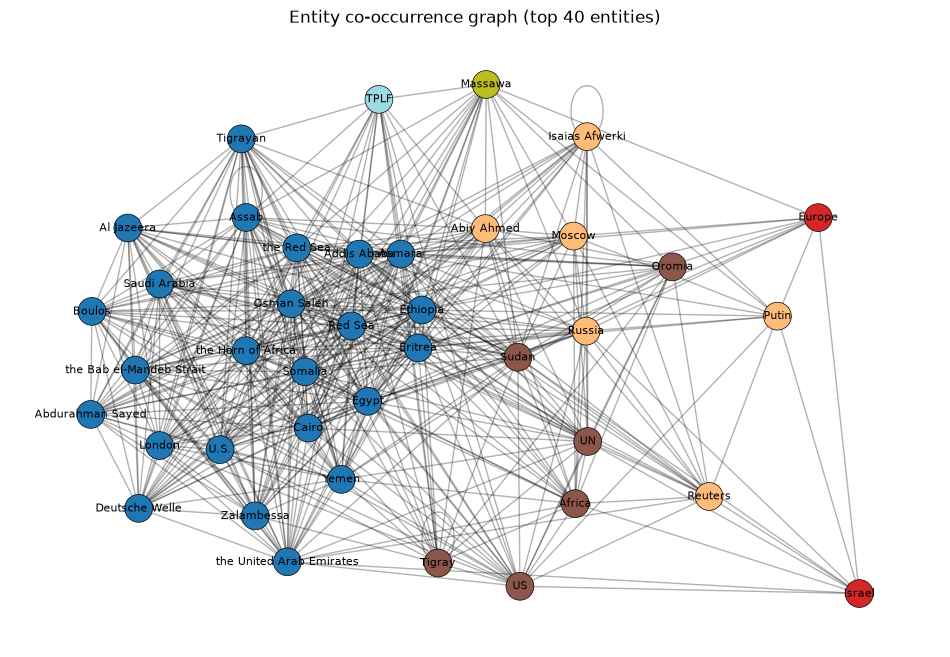

In [17]:
# Draw the 40 best-connected entities, coloured by community
keep = sorted(graph.nodes, key=lambda n: graph.degree(n, weight="weight"), reverse=True)[:40]
sub = graph.subgraph(keep)
node_community = {n: i for i, c in enumerate(communities) for n in c}

plt.figure(figsize=(12, 8))
pos = nx.spring_layout(sub, seed=42, k=1.2)
nx.draw_networkx_edges(sub, pos, alpha=0.3)
nx.draw_networkx_nodes(sub, pos, node_size=400, cmap="tab20",
                       node_color=[node_community[n] for n in sub.nodes],
                       edgecolors="black", linewidths=0.5)
nx.draw_networkx_labels(sub, pos, font_size=8)
plt.title("Entity co-occurrence graph (top 40 entities)")
plt.axis("off")
plt.show()

## Step 6: Retrieval (the "R" in GraphRAG)

Given a question we gather context from **three** sources, then merge them:

1. **Graph:** entities named in the question → the articles that mention them
2. **Graph:** entities that co-occur with them (extra clues)
3. **Keyword:** the full-text index over article titles and texts

### 6a. Find the entities mentioned in the question

In [18]:
question = "What topics connect Eritrea and Russia?"

matched = run("""
    MATCH (e:Entity)
    WHERE size(e.name) > 2 AND toLower($q) CONTAINS toLower(e.name)
    OPTIONAL MATCH (e)-[:MENTIONED_IN]->(a:Article)
    RETURN e.name AS name, e.type AS type, count(a) AS articles
    ORDER BY size(e.name) DESC, articles DESC
    LIMIT 10
""", q=question)

names = [m["name"] for m in matched]
pd.DataFrame(matched)

,name,type,articles
0,Eritrea,GPE,36
1,Russia,GPE,12


### 6b. Articles that mention them (more matching entities = higher rank)

In [19]:
graph_hits = run("""
    MATCH (e:Entity)-[:MENTIONED_IN]->(a:Article)
    WHERE e.name IN $names
    WITH a, count(DISTINCT e) AS hits
    RETURN a.title AS title, a.link AS link, a.source AS source,
           a.text AS text, toFloat(hits) AS score
    ORDER BY hits DESC LIMIT 5
""", names=names)

pd.DataFrame(graph_hits)[["title", "score"]]

,title,score
0,"Peace Through Sovereignty, Truth, and Mutual R...",2.0
1,"Eritrea–Russia Talks Focus on Ports, Railways ...",2.0
2,"Peace Through Sovereignty, Truth, and Mutual R...",2.0
3,"Eritrea–Russia Talks Focus on Ports, Railways ...",2.0
4,From Abiy’s Medemer to Gaddafi’s Green Book: T...,2.0


### 6c. Related entities (neighbours in the graph)

In [20]:
related = run("""
    MATCH (e:Entity)-[r:CO_OCCURS_WITH]-(o:Entity)
    WHERE e.name IN $names AND NOT o.name IN $names
    RETURN o.name AS name, o.type AS type, sum(r.weight) AS weight
    ORDER BY weight DESC LIMIT 10
""", names=names)

pd.DataFrame(related)

,name,type,weight
0,Ethiopia,GPE,30
1,Isaias Afwerki,PERSON,17
2,Asmara,GPE,16
3,Moscow,GPE,15
4,Abiy Ahmed,PERSON,15
5,Addis Ababa,GPE,13
6,Sudan,GPE,12
7,Red Sea,LOC,11
8,Egypt,GPE,9
9,the Red Sea,LOC,9


### 6d. Keyword search with the full-text index

We drop stop-words and join the remaining words with `OR`. Because we only keep letters, digits, `'` and `-`, no Lucene special characters can break the query.

In [21]:
STOP_WORDS = {
    "the", "and", "for", "with", "what", "that", "from", "about", "into", "over",
    "this", "these", "those", "have", "been", "their", "there", "will", "your",
    "are", "was", "were", "but", "not", "than", "then", "also", "more", "how",
    "why", "who", "when", "where", "which", "between", "connect", "topics",
}


def tokens(text):
    seen, out = set(), []
    for tok in re.findall(r"[\w'-]+", text.lower()):
        if len(tok) > 2 and tok not in STOP_WORDS and tok not in seen:
            seen.add(tok)
            out.append(tok)
    return out


print(tokens(question))

keyword_hits = run("""
    CALL db.index.fulltext.queryNodes('article_text', $q) YIELD node, score
    RETURN node.title AS title, node.link AS link, node.source AS source,
           node.text AS text, score
    ORDER BY score DESC LIMIT 5
""", q=" OR ".join(tokens(question)))

pd.DataFrame(keyword_hits)[["title", "score"]]

Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.fulltext.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=5, offset=5>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 5, 'line': 2, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    CALL db.index.fulltext.queryNodes('article_text', $q) YIELD node, score\n    RETURN node.title AS title, node.link AS link, node.source AS source,\n           node.text AS text, score\n    ORDER BY score DESC LIMIT 5\n"


['eritrea', 'russia']


,title,score
0,"Eritrea–Russia Talks Focus on Ports, Railways ...",5.956047
1,Russia Chooses Sudan Over Eritrea,5.492731
2,Moscow witnesses the third Russia – Africa summit,5.187634
3,"Eritrea–Russia Talks Focus on Ports, Railways ...",4.467974
4,Eritrea Seeks to Evade Sanctions Through Russi...,4.467974


## Step 7: Put it together: `retrieve()` and `ask()`

`retrieve()` merges the graph hits (ranked first) and the keyword hits, without duplicates. `ask()` formats the context and returns an answer.

Without an LLM the answer is a short extract from the best articles. With an LLM you pass a function (`llm=`) that receives a prompt and returns text.

In [22]:
def snippet(text, words=60):
    return " ".join(str(text).split()[:words])


def retrieve(question, top_k=5):
    matched = run("""
        MATCH (e:Entity)
        WHERE size(e.name) > 2 AND toLower($q) CONTAINS toLower(e.name)
        OPTIONAL MATCH (e)-[:MENTIONED_IN]->(a:Article)
        RETURN e.name AS name, e.type AS type, count(a) AS articles
        ORDER BY size(e.name) DESC, articles DESC LIMIT 10
    """, q=question)
    names = [m["name"] for m in matched]

    graph_hits = run("""
        MATCH (e:Entity)-[:MENTIONED_IN]->(a:Article)
        WHERE e.name IN $names
        WITH a, count(DISTINCT e) AS hits
        RETURN a.title AS title, a.link AS link, a.source AS source,
               a.text AS text, toFloat(hits) AS score
        ORDER BY hits DESC LIMIT $k
    """, names=names, k=top_k) if names else []

    related = run("""
        MATCH (e:Entity)-[r:CO_OCCURS_WITH]-(o:Entity)
        WHERE e.name IN $names AND NOT o.name IN $names
        RETURN o.name AS name, sum(r.weight) AS weight
        ORDER BY weight DESC LIMIT 10
    """, names=names) if names else []

    terms = tokens(question)
    keyword_hits = run("""
        CALL db.index.fulltext.queryNodes('article_text', $q) YIELD node, score
        RETURN node.title AS title, node.link AS link, node.source AS source,
               node.text AS text, score
        ORDER BY score DESC LIMIT $k
    """, q=" OR ".join(terms), k=top_k) if terms else []

    merged = {}
    for hit in graph_hits + keyword_hits:        # graph hits come first
        merged.setdefault(hit["title"], hit)

    return {"entities": matched, "related": related, "articles": list(merged.values())[:top_k]}


def ask(question, top_k=5, llm=None):
    ctx = retrieve(question, top_k)
    sources = [{"title": a["title"], "link": a["link"]} for a in ctx["articles"]]

    if not ctx["articles"]:
        return {"answer": "I couldn't find anything in the knowledge base about that.", "sources": []}

    context = "\n\n".join(
        [f"Entities: {', '.join(e['name'] for e in ctx['entities'])}",
         f"Co-mentioned: {', '.join(r['name'] for r in ctx['related'])}"]
        + [f"[{i}] {a['title']}\n{snippet(a['text'], 120)}" for i, a in enumerate(ctx["articles"], 1)]
    )

    if llm:
        prompt = ("Answer using ONLY the context below. If it is not enough, say so. "
                  f"Cite article titles.\n\nQuestion: {question}\n\nContext:\n{context}")
        answer = llm(prompt)
    else:
        answer = "Most relevant articles:\n" + "\n".join(
            f"- {a['title']}: {snippet(a['text'], 40)}..." for a in ctx["articles"][:3]
        )
    return {"answer": answer, "sources": sources, "context": context}


reply = ask("What topics connect Eritrea and Russia?")
print(reply["answer"])

Received notification from DBMS server: <GqlStatusObject gql_status='01N01', status_description='warn: feature deprecated with replacement. db.index.fulltext.queryNodes is deprecated. It is replaced by SEARCH.', position=<SummaryInputPosition line=2, column=9, offset=9>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 9, 'line': 2, 'column': 9}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n        CALL db.index.fulltext.queryNodes('article_text', $q) YIELD node, score\n        RETURN node.title AS title, node.link AS link, node.source AS source,\n               node.text AS text, score\n        ORDER BY score DESC LIMIT $k\n    "


Most relevant articles:
- Peace Through Sovereignty, Truth, and Mutual Respect: None...
- Eritrea–Russia Talks Focus on Ports, Railways and Skills: Eritrea and Russia are exploring cooperation to modernise ports and railways and strengthen transport expertise, with Russian companies expressing readiness to participate in infrastructure projects. President Isaias Afwerki met President Vladimir Putin at the Kremlin on 30 October, following separate...
- From Abiy’s Medemer to Gaddafi’s Green Book: The Pretensions of Power: Some leaders or dictators believe that they not only rule a specific country but also contribute greatly to humanity. They believe they have a unique political philosophy and new knowledge, just like a scientific discovery of great value that might...


### Optional: plug in an LLM

Any function `prompt -> text` works. Here is an example with the Anthropic SDK (`pip install anthropic`, `ANTHROPIC_API_KEY` in `.env`). Check the docs for the current model names.

In [23]:
#import anthropic
#client = anthropic.Anthropic()
#def llm(prompt):
#    msg = client.messages.create(
#        model="claude-sonnet-4-5",      # use a model available to you
#        max_tokens=600,
#        messages=[{"role": "user", "content": prompt}],
#    )
#    return msg.content[0].text
# print(ask("What topics connect Eritrea and Russia?", llm=llm)["answer"])

## Step 8: Clean up and go further

Close the driver when you are done:

In [24]:
driver.close()

**Additional works**

1. Raise `N_ARTICLES` to `None` and re-run Steps 1 to 5. How do the communities change?
2. Add `date_raw` to the keyword results so the chatbot can mention when an article was published.
3. Questions only match entity names exactly ("Russia" but not "Russian"). Add an alias table or fuzzy matching to fix that.
4. Add a `Community` node for each community and connect its entities with `BELONGS_TO`, so you can query communities directly in Neo4j.
